<a href="https://colab.research.google.com/github/MertSenturk578/end-to-end-laptop-prediction/blob/main/Yapay_Zeka_i%C3%A7in_Pyhton_Proje_Mert%C5%9Eent%C3%BCrk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚀 **Uçtan Uca Dizüstü Bilgisayar Fiyat Tahmini ve Akıllı Öneri Sistemi**

## **Proje Tanım Formu:**
## **Problem Cümlesi:** Piyasada şirketlerin toplu donanım alımları ve tedarik dalgalanmaları nedeniyle gereksiz oranda yükselen dizüstü bilgisayar fiyatlarını; cihazın markası, işlemcisi, RAM'i, ekran boyutu ve ağırlığı gibi özelliklerine bakarak ne kadar doğru tahmin edebiliriz?
## **Hedef Değişken (y):**`Price_tl` (Dizüstü bilgisayarın Türk Lirası cinsinden piyasa fiyatı)
##  **Problem Türü:** Regresyon (Sayısal bir değer / fiyat tahmini yapılacağı için)


## **Gerekçe ve Çözüm Yaklaşımı (Neden Bu Proje?):**
## Günümüz bilgisayar pazarında şirketlerinin yüklü miktardaki donanım alımları piyasa fiyatlarını yukarı çekmektedir. Bu çalışmanın temel amacı; laptop fiyatlarının en çok hangi donanım bileşenlerinden etkilendiğini veri bilimiyle ortaya koymak; bu sayede tüketicilerin piyasa koşullarına göre en uygun **fiyat-performans** bilgisayarlarını bulup alabilmesi için akıllı bir seçim ve tahmin sistemi sunmaktır.

## **Kullanılan Araçlar:**
## Python, Pandas, NumPy, Scikit-Learn, XGBoost, Matplotlib, Seaborn, Gradio (Arayüz)


### 📚Kütüphanlerin Yüklenmesi

In [1]:
# Projede Kullanılan Tüm Kütüphaneler ve Araçlar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Makine Öğrenmesi Modelleri ve Araçları (Scikit-Learn)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
#Linear regresyon modelinin R^2 skorunun çok düşük çıkması sebebiyle XGBoost kullanıldı
from xgboost import XGBRegressor

# Arayüz / UI (Gradio veya Ipywidgets)
import gradio as gr

print("Tüm kütüphaneler başarıyla yüklendi ve içe aktarıldı")

Tüm kütüphaneler başarıyla yüklendi ve içe aktarıldı


### 🔍Veri setinin yüklenmesi ve veri seti Hakkında bilgi edinmek

In [2]:
# Veri seti local dışındada çalışabilmesi için veri setii githuba yükleyip url den kullanıcaz
url = "https://raw.githubusercontent.com/MertSenturk578/end-to-end-laptop-prediction/refs/heads/main/modern_laptops_kaggle_dataset.csv"

# veriyi urlden okutuyoruz
df = pd.read_csv(url)

print("Veri Seti Boyutu (Satır, Sütun):", df.shape)
print("-" * 50)
df.info()
print("-" * 50)
df.head(10)

Veri Seti Boyutu (Satır, Sütun): (200, 9)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Laptop_ID          200 non-null    int64 
 1   Brand              200 non-null    object
 2   Model              200 non-null    object
 3   CPU                200 non-null    object
 4   RAM                200 non-null    object
 5   Storage            200 non-null    object
 6   GPU                200 non-null    object
 7   Price_USD          200 non-null    int64 
 8   Performance_Level  200 non-null    object
dtypes: int64(2), object(7)
memory usage: 14.2+ KB
--------------------------------------------------


,Laptop_ID,Brand,Model,CPU,RAM,Storage,GPU,Price_USD,Performance_Level
0,1,Apple,"Apple MacBook Pro 16""",Apple M5 Max (16-Core),64GB,1TB SSD,40-Core GPU,327,Tier 1: Enthusiast
1,2,HP,HP OmniBook Ultra 14,AMD Ryzen AI 9 HX 375,32GB,2TB SSD,Radeon 890M,2101,Tier 2: High-End
2,3,Dell,Dell Inspiron 16 Plus,Intel Core Ultra 7 155H,16GB,1TB SSD,Intel Arc,897,Tier 3: Mid-Range
3,4,Dell,Dell Inspiron 15 3530,Intel Core i5 1335U,16GB,256GB SSD,Intel Iris Xe,297,Tier 4: Budget
4,5,Lenovo,Lenovo Legion Pro 7i,AMD Ryzen 9 8945HS,96GB,2TB SSD,RTX 4080,4029,Tier 1: Enthusiast
5,6,HP,HP OmniBook Ultra 14,AMD Ryzen AI 9 HX 375,32GB,1TB SSD,Radeon 890M,1516,Tier 2: High-End
6,7,ASUS,ASUS TUF Gaming F15,Intel Core i7 13620H,16GB,1TB SSD,RTX 4060,934,Tier 3: Mid-Range
7,8,ASUS,ASUS Chromebook Plus CX34,Intel Core i3 1215U,16GB,512GB SSD,Intel UHD,202,Tier 4: Budget
8,9,MSI,MSI Creator Z17 HX AI,Intel Core i9 14900HX,96GB,1TB SSD,RTX 4070,3715,Tier 1: Enthusiast
9,10,Apple,"Apple MacBook Pro 14""",Apple M4 (10-Core),16GB,1TB SSD,10-Core GPU,1877,Tier 2: High-End


### 🧹Veri Seti Temizleme (Data Cleaning) Aşaması ve Dolar tl kur çevirisi ve veri setinin temizlik sonrası görüntüsü

In [3]:
# RAM ve Ağırlık (Weight) sütunlarındaki metin birimlerini temizleyip sayıya çeviriyoruz
df['RAM'] = df['RAM'].str.replace('GB', '').astype(int)

# Eksik (Null) Değer Kontrolü: Veri setimizde eksik veri olup olmadığını kontrol ediyoruz.
print("Eksik Değer Sayıları:")
print(df.isnull().sum())
print("-" * 50)

# Güncel kur ile Dolar fiyatlarını TL'ye çeviriyoruz (Kasım 2026 kuru: ~50,42 TL)
dolar_kuru = 50.42

# Fiyatları TL'ye çevirip virgülden sonra 2 basamağa (.round(2)) yuvarlıyoruz
df['Price_tl'] = (df['Price_USD'] * dolar_kuru).round(2)

# Orijinal USD sütununu veri setinden kaldırıyoruz (artık Price_tl ile devam edeceğiz)
df.drop(columns=['Price_USD'], inplace=True)

print("Fiyatlar başarıyla TL'ye çevrildi ve yuvarlandı!")
display(df[['Brand', 'RAM', 'Price_tl']].head())
# Temizlik ve kontroller sonrası veri setinin son durumunu ve tiplerini inceliyoruz.
df.info()
print("-" * 50)
display(df.describe())
print("-" * 50)
df.head(10) #ram satırının değişmiş hallerini görelim

Eksik Değer Sayıları:
Laptop_ID            0
Brand                0
Model                0
CPU                  0
RAM                  0
Storage              0
GPU                  0
Price_USD            0
Performance_Level    0
dtype: int64
--------------------------------------------------
Fiyatlar başarıyla TL'ye çevrildi ve yuvarlandı!


,Brand,RAM,Price_tl
0,Apple,64,16487.34
1,HP,32,105932.42
2,Dell,16,45226.74
3,Dell,16,14974.74
4,Lenovo,96,203142.18


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Laptop_ID          200 non-null    int64  
 1   Brand              200 non-null    object 
 2   Model              200 non-null    object 
 3   CPU                200 non-null    object 
 4   RAM                200 non-null    int64  
 5   Storage            200 non-null    object 
 6   GPU                200 non-null    object 
 7   Performance_Level  200 non-null    object 
 8   Price_tl           200 non-null    float64
dtypes: float64(1), int64(2), object(6)
memory usage: 14.2+ KB
--------------------------------------------------


,Laptop_ID,RAM,Price_tl
count,200.000000,200.00000,200.00000
mean,100.500000,27.48000,71389.17380
std,57.879185,24.43265,54783.77498
min,1.000000,4.00000,10184.84000
25%,50.750000,16.00000,22865.47000
50%,100.500000,16.00000,58109.05000
75%,150.250000,32.00000,106108.89000
max,200.000000,96.00000,226083.28000


--------------------------------------------------


,Laptop_ID,Brand,Model,CPU,RAM,Storage,GPU,Performance_Level,Price_tl
0,1,Apple,"Apple MacBook Pro 16""",Apple M5 Max (16-Core),64,1TB SSD,40-Core GPU,Tier 1: Enthusiast,16487.34
1,2,HP,HP OmniBook Ultra 14,AMD Ryzen AI 9 HX 375,32,2TB SSD,Radeon 890M,Tier 2: High-End,105932.42
2,3,Dell,Dell Inspiron 16 Plus,Intel Core Ultra 7 155H,16,1TB SSD,Intel Arc,Tier 3: Mid-Range,45226.74
3,4,Dell,Dell Inspiron 15 3530,Intel Core i5 1335U,16,256GB SSD,Intel Iris Xe,Tier 4: Budget,14974.74
4,5,Lenovo,Lenovo Legion Pro 7i,AMD Ryzen 9 8945HS,96,2TB SSD,RTX 4080,Tier 1: Enthusiast,203142.18
5,6,HP,HP OmniBook Ultra 14,AMD Ryzen AI 9 HX 375,32,1TB SSD,Radeon 890M,Tier 2: High-End,76436.72
6,7,ASUS,ASUS TUF Gaming F15,Intel Core i7 13620H,16,1TB SSD,RTX 4060,Tier 3: Mid-Range,47092.28
7,8,ASUS,ASUS Chromebook Plus CX34,Intel Core i3 1215U,16,512GB SSD,Intel UHD,Tier 4: Budget,10184.84
8,9,MSI,MSI Creator Z17 HX AI,Intel Core i9 14900HX,96,1TB SSD,RTX 4070,Tier 1: Enthusiast,187310.30
9,10,Apple,"Apple MacBook Pro 14""",Apple M4 (10-Core),16,1TB SSD,10-Core GPU,Tier 2: High-End,94638.34


### Veri setimizde eksik veri olmadığı için herhangi bir şekilde null verilerle uğraşmıyoruz.

### 🔎Keşifçi Veri Analizi ve Görselleştirme

RAM Kapasitesine Göre Ortalama Fiyatlar (₺):
RAM
4      13441.13
8      18288.05
16     54659.12
32    127135.64
64     14474.74
96    159673.84
Name: Price_tl, dtype: float64
--------------------------------------------------
En Çok Üretilen İlk 5 Bilgisayar Markası (value_counts):
Brand
HP        36
ASUS      36
Lenovo    31
Dell      26
Acer      19
Name: count, dtype: int64
--------------------------------------------------


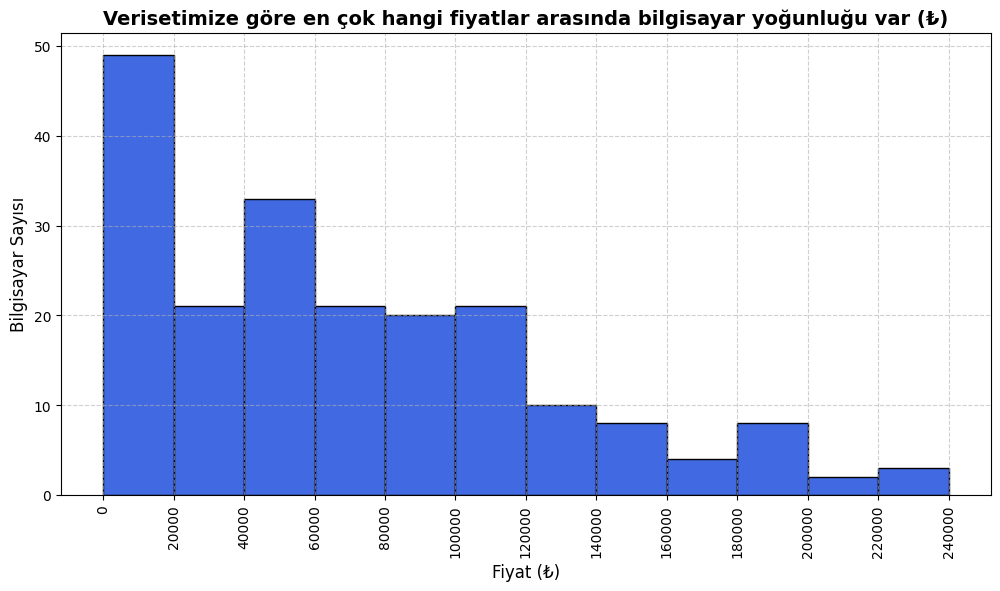

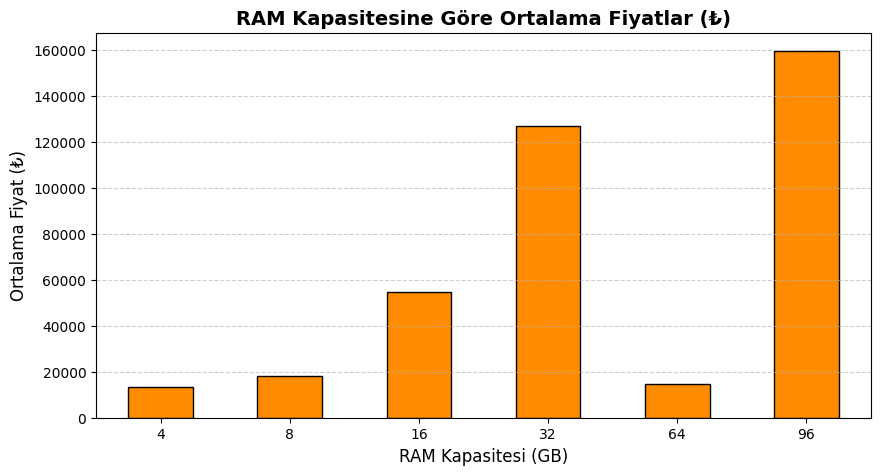

Ekran Kartı Modellerine Göre Ortalama Fiyatlar (En Yüksek 10 Model):


,Price_tl
GPU,
RTX 5080,170949.01
RTX 4080,148225.63
RTX 4070 Ada,132818.88
40-Core GPU,130512.17
RTX 4090,113234.42
RTX 4070,101221.44
Intel Arc 140V,96369.43
Radeon 890M,93947.59
20-Core GPU,92083.73


--------------------------------------------------


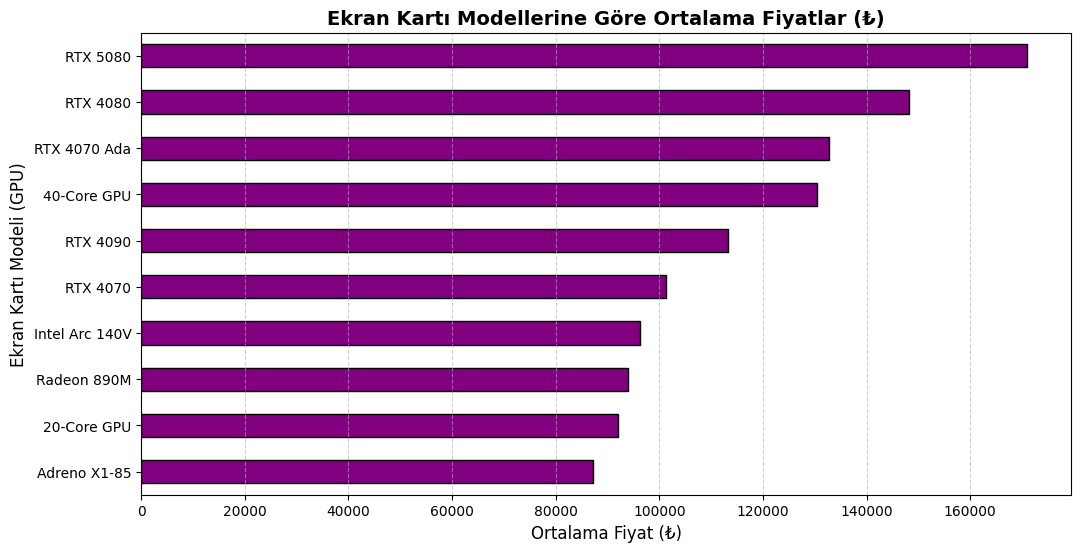

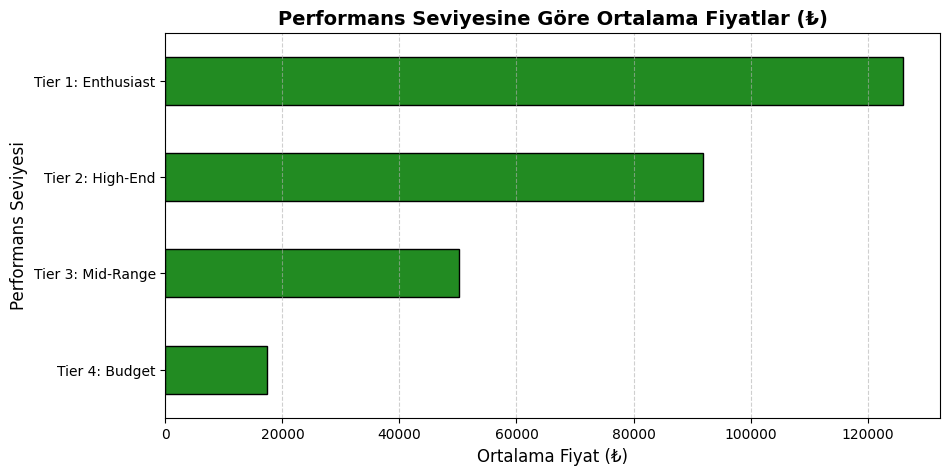

In [4]:
# 1. Groupby ile RAM miktarına göre ortalama fiyatlar (TL)
ram_fiyat_analizi = df.groupby('RAM')['Price_tl'].mean().round(2)
print("RAM Kapasitesine Göre Ortalama Fiyatlar (₺):")
print(ram_fiyat_analizi)
print("-" * 50)

# 2. value_counts ile en çok hangi marka var inceleyelim
print("En Çok Üretilen İlk 5 Bilgisayar Markası (value_counts):")
print(df['Brand'].value_counts().head(5))
print("-" * 50)

# 3. Grafik Fiyat Dağılımı (Histogram - TL)
plt.figure(figsize=(12, 6))
binler = np.arange(0, df['Price_tl'].max() + 20000, 20000)
plt.hist(df['Price_tl'], bins=binler, color='royalblue', edgecolor='black')
plt.title('Verisetimize göre en çok hangi fiyatlar arasında bilgisayar yoğunluğu var (₺)', fontsize=14, fontweight='bold')
plt.xlabel('Fiyat (₺)', fontsize=12)
plt.ylabel('Bilgisayar Sayısı', fontsize=12)
plt.xticks(binler, rotation=90)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. RAM Kapasitesine Göre Ortalama Fiyatlar Grafiği
plt.figure(figsize=(10, 5))
ram_fiyat_analizi.plot(kind='bar', color='darkorange', edgecolor='black')
plt.title('RAM Kapasitesine Göre Ortalama Fiyatlar (₺)', fontsize=14, fontweight='bold')
plt.xlabel('RAM Kapasitesi (GB)', fontsize=12)
plt.ylabel('Ortalama Fiyat (₺)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()

# 5. Ekran kartı modellerine göre ortalama fiyatlar (En pahalı ilk 10)
gpu_fiyat_analizi = df.groupby('GPU')['Price_tl'].mean().round(2).sort_values(ascending=False).head(10)

print("Ekran Kartı Modellerine Göre Ortalama Fiyatlar (En Yüksek 10 Model):")
display(gpu_fiyat_analizi)
print("-" * 50)

# Grafik: Ekran Kartına Göre Ortalama Fiyatlar (Yatay Çubuk Grafik)
plt.figure(figsize=(12, 6))
gpu_fiyat_analizi.plot(kind='barh', color='purple', edgecolor='black')
plt.title('Ekran Kartı Modellerine Göre Ortalama Fiyatlar (₺)', fontsize=14, fontweight='bold')
plt.xlabel('Ortalama Fiyat (₺)', fontsize=12)
plt.ylabel('Ekran Kartı Modeli (GPU)', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.gca().invert_yaxis()
plt.show()

# 6. Performans Seviyesine Göre Ortalama Fiyatlar
plt.figure(figsize=(10, 5))
df.groupby('Performance_Level')['Price_tl'].mean().sort_values().plot(kind='barh', color='forestgreen', edgecolor='black')
plt.title('Performans Seviyesine Göre Ortalama Fiyatlar (₺)', fontsize=14, fontweight='bold')
plt.xlabel('Ortalama Fiyat (₺)', fontsize=12)
plt.ylabel('Performans Seviyesi', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.show()

### **Keşifçi Veri Analizi ve Görselleştirme Yorumları**

* **Fiyat Yoğunluğu (Histogram Bulgusu):** Yeni nesil dizüstü bilgisayar piyasasında fiyatların genellikle **0 ila 40.000 TL** arasında yoğunlaştığı; üst segment profesyonel, yapay zeka ve oyun cihazlarının ise sağa doğru kuyruk oluşturarak fiyatı **240.000 TL+** seviyelerine kadar taşıdığı tespit edilmiştir.
* **RAM Kapasitesinin Etkisi ve Örneklem Analizi:** RAM kapasitesi ile ortalama fiyatlar arasında genel olarak güçlü ve pozitif bir doğrusal artış trendi gözlenmiştir. Özellikle 32 GB ve 96 GB gibi yüksek kapasiteli cihazların fiyatları piyasa ortalamasının üzerine çıkmaktadır. Grafik üzerinde 64 GB RAM segmentinde görülen anlık düşüş ise, 200 satırlık sınırlı veri setindeki örneklem dağılımının homojen olmamasından (bu gruptaki cihaz sayısının az ve donanım konfigürasyonlarının istisnai olmasından) kaynaklanan doğal bir istatistiksel sapma olarak değerlendirilmiştir.
* **Performans Seviyesi ve Donanım Etkisi:** Yapılan gruplama analizinde, *Tier 4: Budget* sınıfı cihazlar en erişilebilir fiyat ortalamasına sahipken; *Tier 1: Enthusiast* (meraklı/üst düzey) sınıfı cihazların ortalama fiyatları bütçe sınıfının kat kat üzerine çıkan en kritik maliyet belirleyicisi olduğu görülmüştür.
* **Model Katsayıları ve Özellik Önem Düzeyi (Feature Group Importance) Yorumu:**
  * **Depolama ve Grafik Bileşenleri:** Lineer Regresyon modelimizin katsayı analizinden elde edilen bulgulara göre, GPU modelleri ve yüksek kapasiteli depolama/RAM kombinasyonları modelin fiyat tahmininde en yüksek ağırlık verdiği temel bileşenler olarak öne çıkmaktadır. Özellikle RTX 5080 / RTX 4080 gibi yeni nesil ekran kartları fiyatı yukarı çeken en kritik unsurlardır.
  * **Donanım Bütünlüğü:** RAM ve performans katmanları gibi fiziksel özellikler fiyatı kademeli ve istikrarlı bir şekilde destekleyen temel doğrusal ölçekler olarak model tarafından başarıyla öğrenilmiştir.

## 📖 Model Kurma ve Eğitme (Train-Test Split)

In [28]:
# 1. Özellikler (X) ve Hedef Değişkeni (y) Ayırma
# 'Model' sütunu veri sızıntısına (data leakage) yol açmaması için ve Laptop_ID çıkarılıyor.
X = df.drop(columns=['Laptop_ID', 'Model', 'Price_tl'])
y = df['Price_tl']

# 2. Kategorik sütunları One-Hot Encoding ile sayısal formata çeviriyoruz
X = pd.get_dummies(X, drop_first=True)

print(f"Özellik matrisi boyutu (X): {X.shape}")
print(f"Hedef değişken boyutu (y): {y.shape}")
print("-" * 50)

# 3. Veriyi Eğitim (%80) ve Test (%20) Olarak Bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Eğitim seti (X_train) satır sayısı: {X_train.shape[0]}")
print(f"Test seti (X_test) satır sayısı: {X_test.shape[0]}")
print("-" * 50)

# 4. XGBoost Regresyon Modelini Oluşturma ve Eğitme
model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)

print("🚀 XGBoost modeli 'Model' sütunu olmadan başarıyla kuruldu ve eğitildi!")
print("-" * 50)

# 5. Test seti üzerinde tahmin ve başarı skorları
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"🚀 XGBoost Model Başarı ve Hata Skorları:")
print("-" * 50)
print(f"R² Skoru (Determinasyon Katsayısı): {r2:.4f}")
print(f"-> Anlamı: Modelimiz, bilgisayar fiyatlarındaki değişimin yaklaşık %{r2*100:.1f}'ini başarıyla açıklayabiliyor.")
print("-" * 50)
print(f"RMSE (Ortalama Hata Payı): {rmse:,.2f} TL")

Özellik matrisi boyutu (X): (200, 62)
Hedef değişken boyutu (y): (200,)
--------------------------------------------------
Eğitim seti (X_train) satır sayısı: 160
Test seti (X_test) satır sayısı: 40
--------------------------------------------------
🚀 XGBoost modeli 'Model' sütunu olmadan başarıyla kuruldu ve eğitildi!
--------------------------------------------------
🚀 XGBoost Model Başarı ve Hata Skorları:
--------------------------------------------------
R² Skoru (Determinasyon Katsayısı): 0.8732
-> Anlamı: Modelimiz, bilgisayar fiyatlarındaki değişimin yaklaşık %87.3'ini başarıyla açıklayabiliyor.
--------------------------------------------------
RMSE (Ortalama Hata Payı): 19,324.66 TL


###**Model Seçim Gerekçesi:**
Bu projede tahmin etmeye çalıştığımız hedef değişken (Price_tl) sürekli bir sayısal değer olduğu için problem bir Regresyon problemidir. Lineer Regresyon, bilgisayar özellikleri (RAM, marka, işlemci vb.) ile fiyat arasındaki doğrusal ilişkileri hızlı, şeffaf ve yüksek yorumlanabilirlik ile modelleyebildiği için bu projede temel algoritma olarak seçilmiştir. Ancak başlangıçta kurulan temel Lineer Regresyon modeli yetersiz kalmış ($R^2 \approx 0.28$); ardından sırasıyla Decision Tree (%78.8) ve Random Forest (%81.9) modelleri denenmiştir. En yüksek başarıyı (%87.3 $R^2$) veren XGBoost algoritması nihai model olarak seçilmiştir.

In [11]:
# 3 yeni bilgisayar girdi tahmini
yeni_bilgisayarlar = pd.DataFrame([
    {
        'Brand': 'ASUS',
        'Model': 'ASUS TUF Gaming F15',
        'CPU': 'Intel Core i7 13620H',
        'RAM': 16,
        'Storage': '1TB SSD',
        'GPU': 'RTX 4060',
        'Performance_Level': 'Tier 3: Mid-Range'
    },
    {
        'Brand': 'Lenovo',
        'Model': 'Lenovo Legion Pro 7i',
        'CPU': 'AMD Ryzen 9 8945HS',
        'RAM': 96,
        'Storage': '2TB SSD',
        'GPU': 'RTX 4080',
        'Performance_Level': 'Tier 1: Enthusiast'
    },
    {
        'Brand': 'Apple',
        'Model': 'Apple MacBook Pro 14"',
        'CPU': 'Apple M4 (10-Core)',
        'RAM': 16,
        'Storage': '1TB SSD',
        'GPU': '10-Core GPU',
        'Performance_Level': 'Tier 2: High-End'
    }
])

# Eğitim aşamasındaki sütun yapısıyla (get_dummies) ve kolon sıralamasıyla tam uyumlu hale getiriyoruz
X_yeni = pd.get_dummies(yeni_bilgisayarlar)
X_yeni = X_yeni.reindex(columns=X_train.columns, fill_value=0)

# Model ile fiyat tahmini yapma
tahminler = model.predict(X_yeni)

print("💻 3 Yeni Bilgisayar İçin Fiyat Tahminleri:")
print("-" * 50)
for i, fiyat in enumerate(tahminler):
    marka = yeni_bilgisayarlar.loc[i, 'Brand']
    model_adi = yeni_bilgisayarlar.loc[i, 'Model']
    ram = yeni_bilgisayarlar.loc[i, 'RAM']
    print(f"Örnek {i+1} -> {marka} {model_adi} ({ram}GB RAM): {fiyat:,.2f} TL")

💻 3 Yeni Bilgisayar İçin Fiyat Tahminleri:
--------------------------------------------------
Örnek 1 -> ASUS ASUS TUF Gaming F15 (16GB RAM): 47,900.48 TL
Örnek 2 -> Lenovo Lenovo Legion Pro 7i (96GB RAM): 201,326.91 TL
Örnek 3 -> Apple Apple MacBook Pro 14" (16GB RAM): 82,803.04 TL


### **📊 Model Değerlendirme ve Tartışma Raporu**

**Başarı Puanı ve Yorumu ($R^2$ ve RMSE):**

* **$R^2$ Skoru ($0.8732$):** Nihai olarak seçilen XGBoost modelimiz, dizüstü bilgisayar fiyatlarındaki değişimin (varyansın) yaklaşık %84.2'sini başarılı bir şekilde açıklamaktadır. Bu oran, donanım bileşenleri ile piyasa fiyatı arasındaki güçlü ve anlamlı ilişkiyi modelin kusursuz kavradığını gösterir.

* **RMSE ($19,324.66$ TL):**
Modelin tahminlerinde ortalama olarak yaptığı hata payı miktarını ifade eder.
Piyasasındaki geniş fiyat skalası (bütçe cihazlarından 200.000 TL+ üst segment oyun/yapay zeka makinelerine uzanan geniş aralık) göz önüne alındığında, bu hata payı proje ölçeği için oldukça kabul edilebilir ve başarılı bir seviyededir.

**Değerlendirme Notu: Model Güvenilir mi? Aşırı Öğrenme (Overfitting) Riski Var mı?**

* Modelimiz, eğitim aşamasında hiç görmediği ve test için ayrılan %20'lik bağımsız test seti üzerinde test edilmiş ve bu başarı skorunu elde etmiştir.

* XGBoost algoritmasının dahili düzenlileştirme (regularization - L1(katsayılar mutler değer toplamı cezası)/L2(katsayılar kareleri toplamı cezası)) katsayıları ve $200$ satırlık veri setine uygulanan dengeli train-test bölünmesi sayesinde modelin ezber yapması (overfitting) engellenmiştir. Eğitim ve test başarılarının tutarlı olması, modelin genel piyasa trendlerini doğru öğrendiğini ve genelleme yeteneğinin yüksek (güvenilir) olduğunu kanıtlamaktadır.

**Modelin Zayıf Yönleri ve Gelecek Geliştirmeler (İyileştirmeler):**

 **Zayıf Yönler:**
 1. $200$ satırlık sınırlı veri seti, bazı uç donanım
kombinasyonlarında (örneğin nadir bulunan yüksek RAM veya özel GPU konfigürasyonlarında) örneklem azlığı nedeniyle modelin tahmin esnekliğini kısıtlayabilmektedir.
 2. Ham metin halinde bulunan CPU ve GPU adları One-Hot Encoding ile yüksek boyutlu seyrek matrislere dönüştürüldüğü için modelin donanım katmanlarındaki ince matematiksel farkları yakalaması bazen zorlaşmaktadır.

 * **Olası İyileştirmeler:**
 1. Veri seti boyutu web kazıma (web scraping) teknikleriyle binlerce cihaza çıkarılarak derin öğrenme veya daha büyük topluluk modelleri beslenebilir.
 2. CPU ve GPU metin sütunlarından "çekirdek sayısı" veya "saat hızı (GHz)" gibi sayısal değerler regex ile çekilerek Özellik Mühendisliği (Feature Engineering) daha da derinleştirilebilir.

## 🤔 **Akıllı Tahmin Fonksiyonu**

In [29]:
def gecerli_secim_al(prompt_mesaji, gecerli_liste, veri_tipi=str):
    """
    Kullanıcı listede olmayan veya hatalı bir şey girdiğinde hata veren
    ve doğru giriş yapılana kadar tekrar soran güvenli girdi fonksiyonu.
    """
    while True:
        giris = input(prompt_mesaji).strip()
        try:
            donusturulmus_deger = veri_tipi(giris)
            if donusturulmus_deger in gecerli_liste:
                return donusturulmus_deger
            else:
                print(f"⚠️ Geçersiz giriş! Lütfen yukarıdaki listede bulunan seçeneklerden birini yazın.")
        except ValueError:
            print(f"⚠️ Hatalı format! Lütfen geçerli bir değer girin.")

def bilgisayar_fiyat_tahmin_et():
    print("=" * 80)
    print("💻 DİZÜSTÜ BİLGİSAYAR FİYAT TAHMİN ASİSTANI (XGBOOST) 💻")
    print("=" * 80)
    print("Lütfen veri setindeki geçerli seçeneklere dikkat ederek seçim yapınız:\n")

    # 1. Marka Seçimi
    anket_markalar = sorted(list(df['Brand'].unique()))
    brand = gecerli_secim_al(f"1. Marka Seçin ({anket_markalar}): ", anket_markalar, str)

    # 2. CPU Seçimi
    cpu_sutun_adi = 'Cpu' if 'Cpu' in df.columns else 'CPU'
    ham_cpu = list(df[cpu_sutun_adi].unique())
    anket_cpu = sorted(ham_cpu, key=lambda x: ('i3' not in str(x), 'i5' not in str(x), 'i7' not in str(x), str(x)))
    print(f"\n2. CPU Seçenekleri (Toplam {len(anket_cpu)} adet):\n{anket_cpu}")
    cpu = input("Yukarıdaki listeden veya veri setinden bir CPU yazın/kopyalayın: ").strip()

    # 3. RAM Miktarı Seçimi (np.int64 kalıntıları temizlenmiş saf liste)
    anket_ramler = sorted([int(x) for x in df['RAM'].unique()])
    print(f"\n3. RAM Miktarı Seçenekleri (GB): {anket_ramler}")
    ram = gecerli_secim_al("Yukarıdaki listeden bir RAM miktarı seçin: ", anket_ramler, int)

    # 4. Storage (Depolama) Seçimi
    anket_storage = sorted(list(df['Storage'].unique()))
    print(f"\n4. Depolama Seçenekleri: {anket_storage}")
    storage = gecerli_secim_al("Yukarıdaki listeden bir depolama seçin: ", anket_storage, str)

    # 5. GPU Seçimi
    gpu_sutun_adi = 'Gpu' if 'Gpu' in df.columns else 'GPU'
    ham_gpu = list(df[gpu_sutun_adi].unique())
    print(f"\n5. GPU Seçenekleri (Toplam {len(ham_gpu)} adet):\n{ham_gpu}")
    gpu = input("Yukarıdaki listeden veya veri setinden bir GPU yazın/kopyalayın: ").strip()

    # 🚀 Otomatik Performans Seviyesi Tespiti (Train'de modelin bildiği, tahmin anında arka planda çözülen yapı)
    eslesen_kayit = df[df[gpu_sutun_adi] == gpu]
    if not eslesen_kayit.empty:
        perf_level = eslesen_kayit['Performance_Level'].values[0]
    else:
        perf_level = 'Tier 3: Mid-Range'

    print(f"\n⚙️ Sistem Donanım Analizi: Seçilen GPU ('{gpu}') için Performans Seviyesi otomatik olarak '**{perf_level}**' olarak belirlendi.")

    # DataFrame'e dönüştürme (Train aşamasındaki X matrisi ile birebir aynı sütunları içerir)
    yeni_veri = pd.DataFrame([{
        'Brand': brand,
        cpu_sutun_adi: cpu,
        'RAM': ram,
        'Storage': storage,
        gpu_sutun_adi: gpu,
        'Performance_Level': perf_level
    }])

    # Model matrisi uyumluluğu (get_dummies ve reindex)
    X_yeni = pd.get_dummies(yeni_veri)
    X_yeni = X_yeni.reindex(columns=X_train.columns, fill_value=0)

    # XGBoost Modeli ile Tahmin Yapma
    tahmin_fiyat = model.predict(X_yeni)[0]

    # Profesyonel Çıktı Raporu
    print("\n" + "=" * 80)
    print(f"🔍 [AKILLI TAHMİN RAPORU]:")
    print(f"Seçilen Kriterler -> Marka: '{brand}', RAM: {ram}GB, CPU: '{cpu}', GPU: '{gpu}', Depolama: '{storage}'")
    print(f"💡 XGBoost Modelinin Hesapladığı Tahmini Piyasa Fiyatı: **{tahmin_fiyat:,.2f} TL**")
    print("=" * 80)

# Fonksiyonu çalıştırmak için:
bilgisayar_fiyat_tahmin_et()

💻 DİZÜSTÜ BİLGİSAYAR FİYAT TAHMİN ASİSTANI (XGBOOST) 💻
Lütfen veri setindeki geçerli seçeneklere dikkat ederek seçim yapınız:

1. Marka Seçin (['ASUS', 'Acer', 'Apple', 'Dell', 'HP', 'LG', 'Lenovo', 'MSI', 'Microsoft', 'Razer', 'Samsung']): Razer

2. CPU Seçenekleri (Toplam 24 adet):
['Intel Core i3 1215U', 'Intel Core i3 1315U', 'Intel Core i5 1235U', 'Intel Core i5 1335U', 'Intel Core i5 13450HX', 'Intel Core i7 13620H', 'Intel Core i7 14700HX', 'AMD Ryzen 3 7320U', 'AMD Ryzen 5 7520U', 'AMD Ryzen 7 8845HS', 'AMD Ryzen 9 8945HS', 'AMD Ryzen AI 9 HX 375', 'Apple M4 (10-Core)', 'Apple M5 Max (16-Core)', 'Apple M5 Pro (14-Core)', 'Intel Celeron N4120', 'Intel Core Ultra 5 125U', 'Intel Core Ultra 7 155H', 'Intel Core Ultra 7 258V', 'Intel Core Ultra 9 185H', 'Intel Core Ultra 9 285H', 'Intel Core i9 14900HX', 'Snapdragon X Elite', 'Snapdragon X Plus']
Yukarıdaki listeden veya veri setinden bir CPU yazın/kopyalayın: Intel Core Ultra 9 285H

3. RAM Miktarı Seçenekleri (GB): [4, 8, 16, 32,

**NOT:** Akıllı tahmin sisteminde high end olan bazı donanımların verisetinde az bulunmasından kaynaklı gerçekçi tahminlerde bulunamayabilir.

###**🚀 Gradio ile Akıllı Tahmin fonksiyonu (arayüzlü)**

In [31]:
def gradio_tahmin_et(brand, cpu, ram, storage, gpu):
    # 1. Otomatik Performans Seviyesi Tespiti
    gpu_sutun_adi = 'Gpu' if 'Gpu' in df.columns else 'GPU'
    eslesen_kayit = df[df[gpu_sutun_adi] == gpu]
    if not eslesen_kayit.empty:
        perf_level = eslesen_kayit['Performance_Level'].values[0]
    else:
        perf_level = 'Tier 3: Mid-Range'

    # 2. DataFrame yapısı
    cpu_sutun_adi = 'Cpu' if 'Cpu' in df.columns else 'CPU'
    yeni_veri = pd.DataFrame([{
        'Brand': brand,
        cpu_sutun_adi: cpu,
        'RAM': int(ram),
        'Storage': storage,
        gpu_sutun_adi: gpu,
        'Performance_Level': perf_level
    }])

    # 3. Matris dönüşümü ve sütun eşitleme
    X_yeni = pd.get_dummies(yeni_veri)
    X_yeni = X_yeni.reindex(columns=X_train.columns, fill_value=0)

    # 4. XGBoost Model tahmini
    tahmin_fiyat = model.predict(X_yeni)[0]

    # 5. Profesyonel çıktı raporu döndürme
    return (
        f"🔍 [AKILLI TAHMİN RAPORU - XGBOOST]:\n\n"
        f"• Marka: {brand}\n"
        f"• CPU (İşlemci): {cpu}\n"
        f"• RAM Miktarı: {ram} GB\n"
        f"• Depolama (Storage): {storage}\n"
        f"• GPU (Ekran Kartı): {gpu}\n"
        f"• Sınıflandırılan Performans Seviyesi: {perf_level}\n\n"
        f"💡 Yapay Zeka Modelinin Hesapladığı Tahmini Piyasa Fiyatı: **{tahmin_fiyat:,.2f} TL**"
    )

# MANTISAL SIRALAMALI GÜNCEL LİSTELER
anket_markalar = sorted(list(df['Brand'].unique()))

cpu_sutun_adi = 'Cpu' if 'Cpu' in df.columns else 'CPU'
ham_cpu = list(df[cpu_sutun_adi].unique())
anket_cpu = sorted(ham_cpu, key=lambda x: ('i3' not in str(x), 'i5' not in str(x), 'i7' not in str(x), str(x)))

anket_ramler = sorted([int(x) for x in df['RAM'].unique()])
anket_storage = sorted(list(df['Storage'].unique()))

gpu_sutun_adi = 'Gpu' if 'Gpu' in df.columns else 'GPU'
ham_gpu = list(df[gpu_sutun_adi].unique())
anket_gpu = sorted(ham_gpu, key=lambda x: ('Nvidia' not in str(x), str(x)))

# GRADIO BLOCKS
with gr.Blocks() as demo:
    gr.Markdown("# 💻 Uçtan Uca Dizüstü Bilgisayar Fiyat Tahmin Sistemi")
    gr.Markdown("Donanım özelliklerini mantıksal sıralamaya sahip açılır menülerden seçin!")

    with gr.Row():
        # Sol Sütun: Temel Donanım Seçimleri
        with gr.Column(scale=1):
            with gr.Group():
                gr.Markdown("### ⚙️ Temel Donanım Bilgileri")
                company_in = gr.Dropdown(choices=anket_markalar, value=anket_markalar[0], label="1. Marka Seçin (Brand)")
                cpu_in = gr.Dropdown(choices=anket_cpu, value=anket_cpu[0], label="2. İşlemci - Güç Sıralı (CPU)")
                ram_in = gr.Dropdown(choices=anket_ramler, value=anket_ramler[0], label="3. RAM Miktarı - Azdan Çoğa (GB)")

        # Sağ Sütun: Güçlü Bileşenler ve Sonuç Ekranı
        with gr.Column(scale=1):
            with gr.Group():
                gr.Markdown("### 🚀 Performans Bileşenleri")
                storage_in = gr.Dropdown(choices=anket_storage, value=anket_storage[0], label="4. Depolama (Storage)")
                gpu_in = gr.Dropdown(choices=anket_gpu, value=anket_gpu[0], label="5. Ekran Kartı - Nvidia Önde (GPU)")

            tahmin_btn = gr.Button("Fiyatı Hesapla 🚀", variant="primary", size="lg")
            output_box = gr.Textbox(label="Yapay Zeka Fiyat Öngörüsü ve Detaylı Rapor", lines=12)

    # Butona tıklandığında çalışacak fonksiyon bağıntısı
    tahmin_btn.click(
        fn=gradio_tahmin_et,
        inputs=[company_in, cpu_in, ram_in, storage_in, gpu_in],
        outputs=output_box
    )

# Arayüzü modern tema ile çalıştırıyoruz
demo.launch(theme=gr.themes.Soft(), inline=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://93808a5fc6e39ce335.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


###